In [1]:
# Importing the Library
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Loading and displaying the first 10 rows of the dataset
df = pd.read_excel("stock_risk_prediction_dataset.xlsx")
df.head(4)

,current_stock,avg_daily_demand,lead_time_days,reorder_point,sales_last_30_days,stock_turnover_ratio,forecast_error,season,item_category,supplier_reliability,stock_status
0,549,45.76,5.64,342.83,1604.49,4.17,-9.90,peak,essential,low,overstock
1,486,45.47,6.39,348.37,1585.00,4.01,-5.27,peak,non-essential,high,overstock
2,564,32.04,5.81,353.21,1219.04,3.57,-2.94,off-peak,non-essential,high,overstock
3,652,46.70,7.22,397.34,1673.88,4.00,0.75,off-peak,essential,low,overstock


In [3]:
# Checking the shape of the dataset
print('The shape of the data set is : ',df.shape)

The shape of the data set is :  (5000, 11)


In [4]:
# Checking the size of the dataset
print('The size of the data set is : ',df.size)

The size of the data set is :  55000


In [5]:
# To get the information of the entire dataset
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   current_stock         5000 non-null   int64  
 1   avg_daily_demand      5000 non-null   float64
 2   lead_time_days        5000 non-null   float64
 3   reorder_point         5000 non-null   float64
 4   sales_last_30_days    5000 non-null   float64
 5   stock_turnover_ratio  5000 non-null   float64
 6   forecast_error        5000 non-null   float64
 7   season                5000 non-null   object 
 8   item_category         5000 non-null   object 
 9   supplier_reliability  5000 non-null   object 
 10  stock_status          5000 non-null   object 
dtypes: float64(6), int64(1), object(4)
memory usage: 429.8+ KB
None


In [6]:
# Check for the null values
df.isnull().sum().sum() # We don't have any null values

np.int64(0)

In [7]:
# Check for the duplicate values
df.duplicated().sum() # We don't have any duplicates in our dataset

np.int64(0)

In [8]:
# To descibe the entire data set
df.describe()

,current_stock,avg_daily_demand,lead_time_days,reorder_point,sales_last_30_days,stock_turnover_ratio,forecast_error
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,500.065800,49.901224,7.021084,350.825734,1494.494344,3.993402,-0.054578
std,99.647785,10.104358,1.997617,50.166808,295.012442,0.999404,5.129634
min,175.000000,10.780000,0.250000,157.180000,403.470000,0.550000,-22.330000
25%,434.000000,43.130000,5.680000,316.765000,1289.470000,3.300000,-3.540000
50%,501.000000,49.825000,7.020000,350.960000,1497.595000,4.000000,-0.120000
75%,566.000000,56.772500,8.350000,385.332500,1695.180000,4.680000,3.442500
max,892.000000,85.290000,13.860000,573.950000,2583.410000,7.690000,18.640000


In [9]:
# Analysing categorical values
print(df['season'].value_counts())
print('-'*30)
print(df['item_category'].value_counts())
print('-'*30)
print(df['supplier_reliability'].value_counts())
print('-'*30)
print(df['stock_status'].value_counts())

season
off-peak    2508
peak        2492
Name: count, dtype: int64
------------------------------
item_category
essential        2505
non-essential    2495
Name: count, dtype: int64
------------------------------
supplier_reliability
low     2514
high    2486
Name: count, dtype: int64
------------------------------
stock_status
overstock    4543
stockout      457
Name: count, dtype: int64


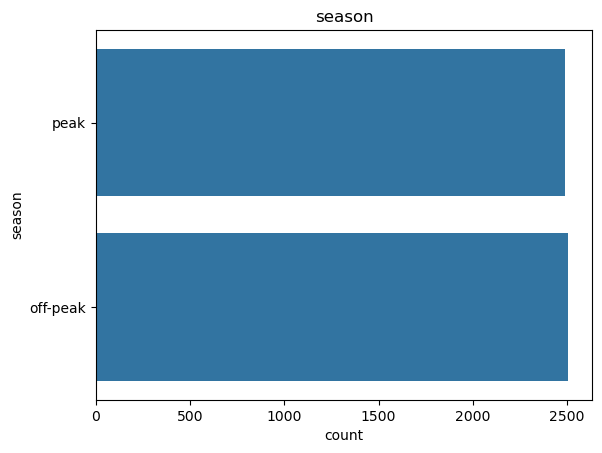

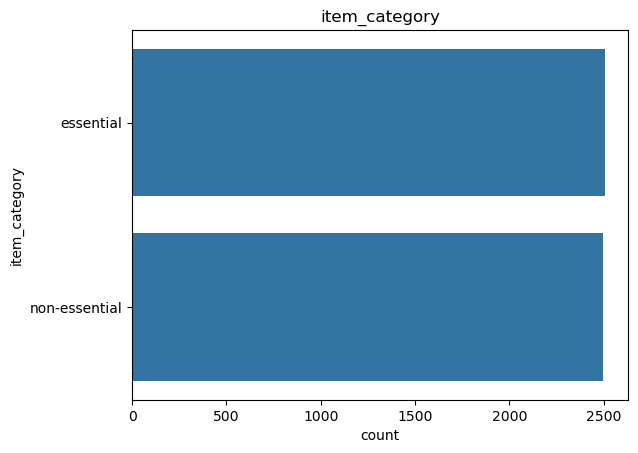

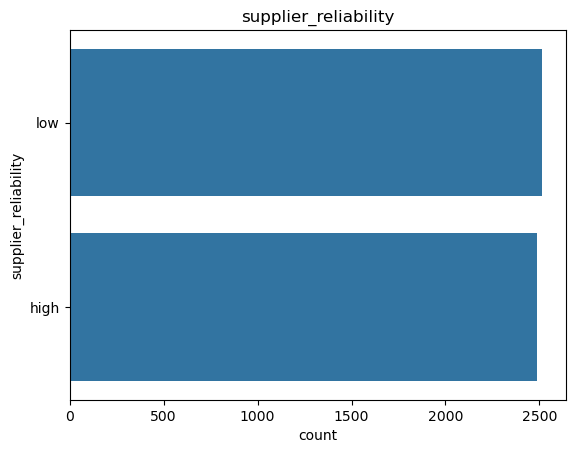

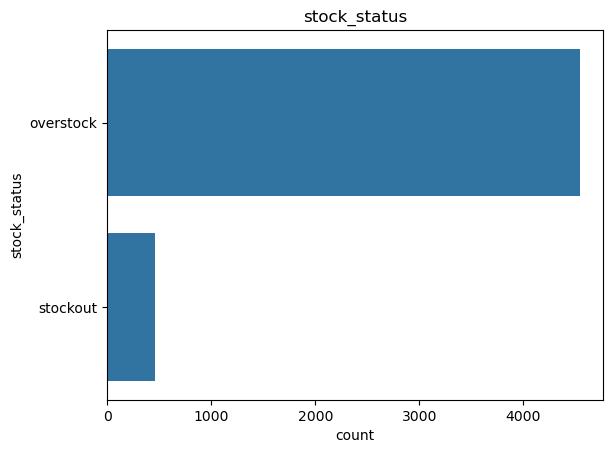

In [10]:
# Graphical representation of the categorical value using count_plot
for j in df.select_dtypes(include=['object']).columns:
    sns.countplot(df[j])
    plt.title(j)
    plt.show()

**stock_status**,
##### **overstock    4543 --> 90.86%,**
##### **stockout      457 --> 9.14%,**
**This means our tager column/class is imblanced. If you train the model directly, it may become biased toward predicting overstock.
Class imbalance should be handled during model building**

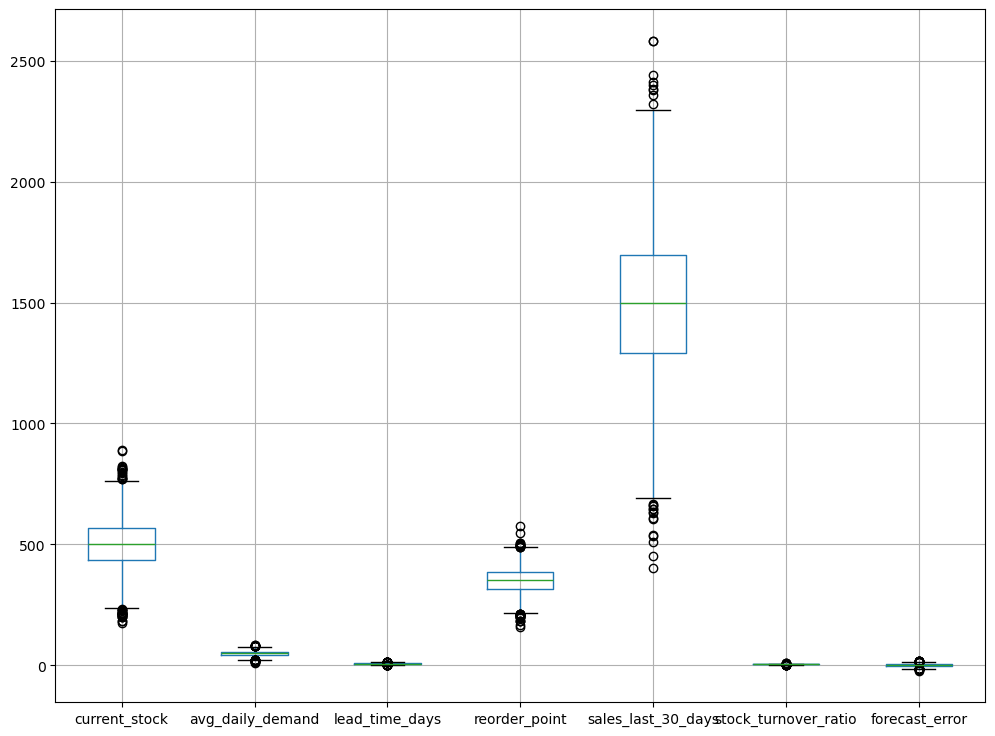

In [11]:
# Checking for the outliers in the dataset using the boxplot
plt.figure(figsize=(12,9))
df.boxplot()
plt.show()
# Here outlier capping in not neede beacause those are the genuine reasons for stock_status(Over_stock/Stock_out)

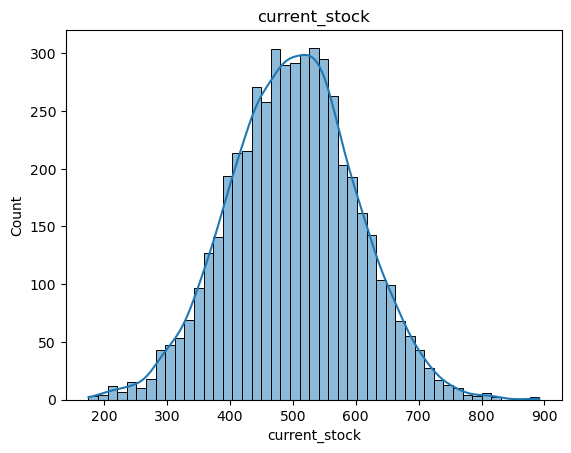

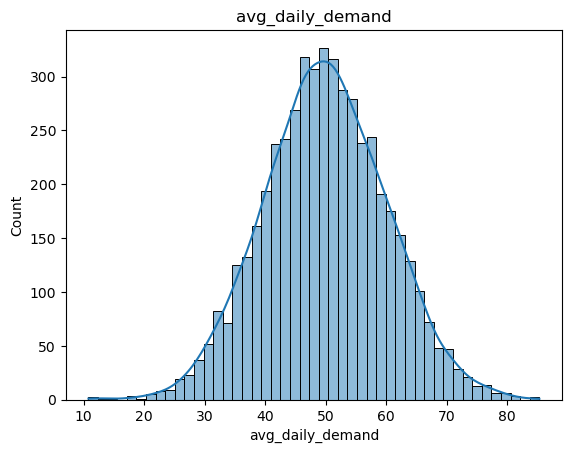

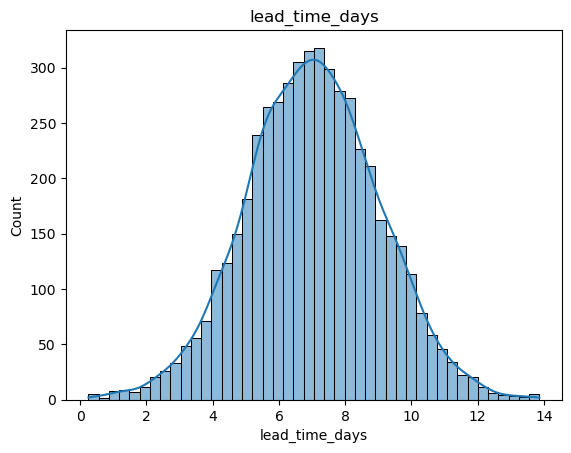

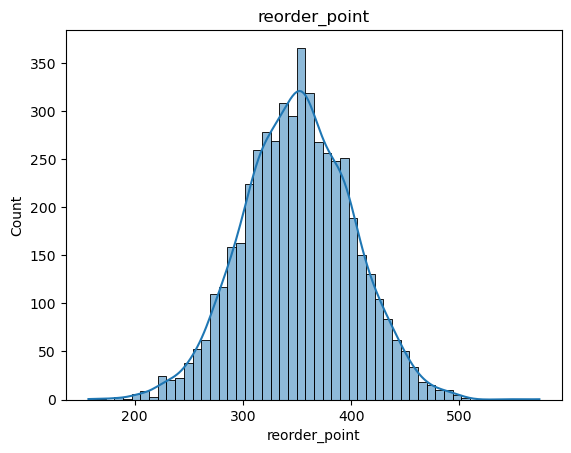

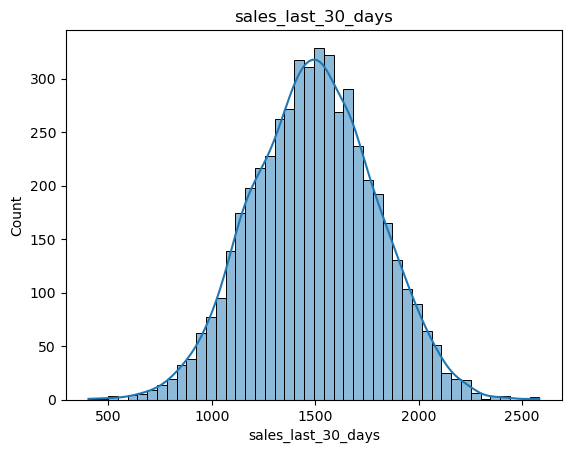

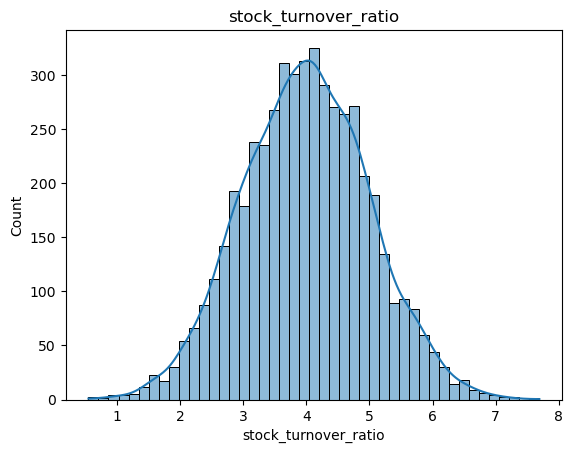

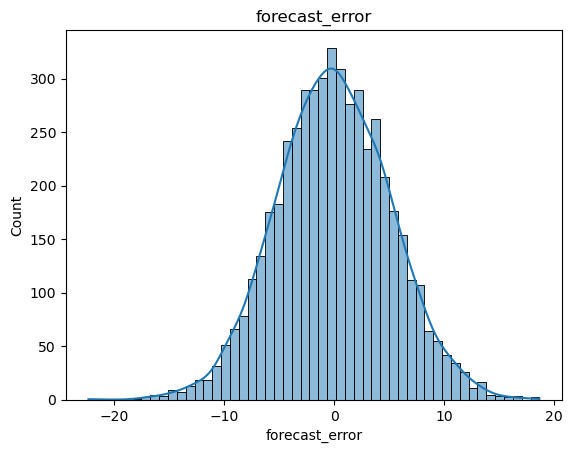

In [12]:
# Graphical representation of the numerical values using histogram
for i in df.select_dtypes(include=['int','float']).columns:
    sns.histplot(df[i], kde=True)
    plt.title(i)
    plt.show()

In [13]:
# Converting Categorical values into numerical using encoders
from sklearn.preprocessing import OrdinalEncoder, LabelEncoder
oe = OrdinalEncoder()
le = LabelEncoder()
df[['season', 'item_category', 'supplier_reliability']] = oe.fit_transform(df[['season', 'item_category', 'supplier_reliability']])
df['stock_status'] = le.fit_transform(df['stock_status'])

In [14]:
df.head(5)

,current_stock,avg_daily_demand,lead_time_days,reorder_point,sales_last_30_days,stock_turnover_ratio,forecast_error,season,item_category,supplier_reliability,stock_status
0,549,45.76,5.64,342.83,1604.49,4.17,-9.90,1.0,0.0,1.0,0
1,486,45.47,6.39,348.37,1585.00,4.01,-5.27,1.0,1.0,0.0,0
2,564,32.04,5.81,353.21,1219.04,3.57,-2.94,0.0,1.0,0.0,0
3,652,46.70,7.22,397.34,1673.88,4.00,0.75,0.0,0.0,1.0,0
4,476,57.33,9.39,312.64,1052.98,4.49,5.12,1.0,0.0,0.0,0


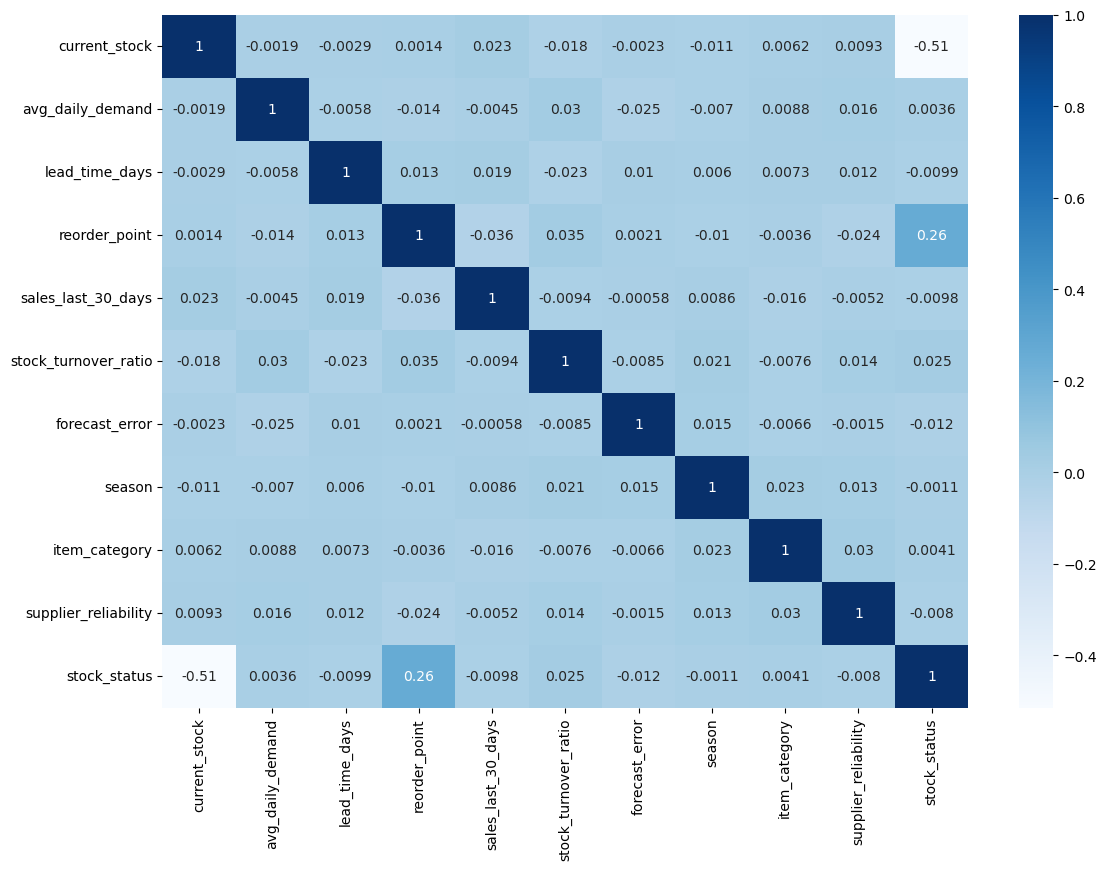

In [15]:
# Displaying the relation between features to the target value using heatmap
plt.figure(figsize=(13,9))
sns.heatmap(df.corr(numeric_only = True), annot = True, cmap = 'Blues')
plt.show()

<Axes: >

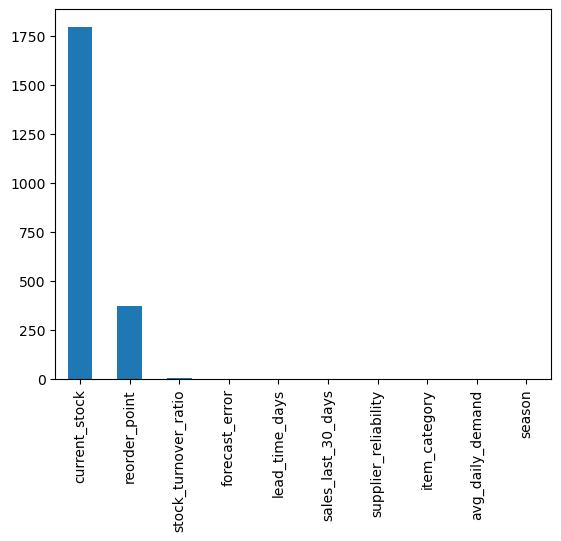

In [16]:
from sklearn.feature_selection import f_classif
features = df.drop(columns = ['stock_status'])
target = df['stock_status']
res = f_classif(features, target)
pd.Series(res[0], index = features.columns).sort_values(ascending = False).plot(kind = 'bar')

In [17]:
from sklearn.model_selection import train_test_split

x = df.drop(columns='stock_status')
y = df['stock_status']

x_train,x_test,y_train,y_test = train_test_split(x, y, test_size=0.3, random_state=40, stratify=y)
x_train = x_train.copy()
x_test = x_test.copy()

**stratify=y is used in train_test_split() to maintain the same proportion of each target class in both training and testing data.**

In [18]:
# Scale the training and testing data
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
x_train_scaled = sc.fit_transform(x_train)
x_test_scaled = sc.transform(x_test)

**Model Building & Evaluation**

Train four classifiers. Logistic Regression and SVC use scaled features; tree models use encoded, unscaled features. All models use class_weight='balanced' to give more influence to the minority stockout class during training.

**Logistic_Regression**

In [19]:
# Train the model
from sklearn.linear_model import LogisticRegression
lr=LogisticRegression(class_weight='balanced',random_state=42)
lr.fit(x_train_scaled,y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,random_state,42
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


Training accuracy: 0.9771428571428571
Testing accuracy: 0.982
Training classification report:
              precision    recall  f1-score   support

           0     1.0000    0.9748    0.9873      3180
           1     0.8000    1.0000    0.8889       320

    accuracy                         0.9771      3500
   macro avg     0.9000    0.9874    0.9381      3500
weighted avg     0.9817    0.9771    0.9783      3500

Testing classification report:
              precision    recall  f1-score   support

           0     1.0000    0.9802    0.9900      1363
           1     0.8354    1.0000    0.9103       137

    accuracy                         0.9820      1500
   macro avg     0.9177    0.9901    0.9501      1500
weighted avg     0.9850    0.9820    0.9827      1500



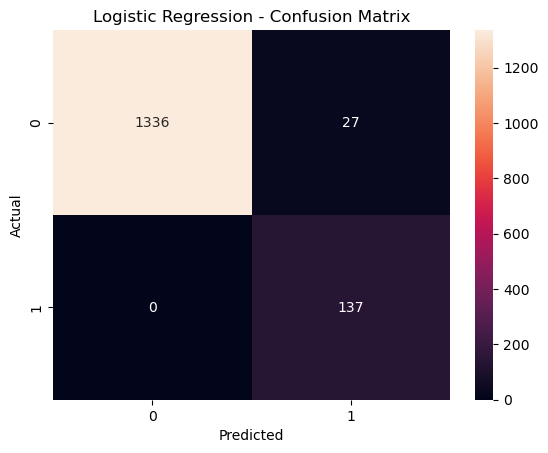

In [20]:
# Evaluate the Logistic Regression model
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix
pred_train_lr=lr.predict(x_train_scaled)
pred_test_lr=lr.predict(x_test_scaled)
print('Training accuracy:',accuracy_score(y_train,pred_train_lr))
print('Testing accuracy:',accuracy_score(y_test,pred_test_lr))
print('Training classification report:')
print(classification_report(y_train,pred_train_lr,digits=4,zero_division=0))
print('Testing classification report:')
print(classification_report(y_test,pred_test_lr,digits=4,zero_division=0))
sns.heatmap(confusion_matrix(y_test,pred_test_lr),annot=True,fmt='d')
plt.title('Logistic Regression - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

ROC-AUC: 0.9997161692488125


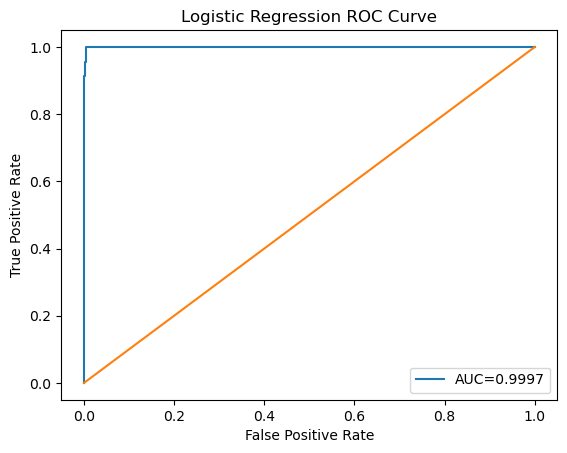

In [21]:
# Calculate Logistic Regression probabilities , AUC and Plotting ROC Curve
from sklearn.metrics import roc_auc_score,roc_curve
sigmoid=lr.predict_proba(x_test_scaled)[:,1]
auc_score=roc_auc_score(y_test,sigmoid)
print('ROC-AUC:',auc_score)

# Plot the ROC curve
fpr,tpr,thr=roc_curve(y_test,sigmoid)
plt.plot(fpr,tpr,label=f'AUC={auc_score:.4f}')
plt.plot([0,1],[0,1])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Logistic Regression ROC Curve')
plt.legend()
plt.show()

**Logistic_Regression using HyperParameter_Tuning**

In [22]:
# Tune Logistic Regression using a pipeline
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
lr_pipeline=Pipeline([
    ('scaler',StandardScaler()),
    ('lr',LogisticRegression(class_weight='balanced',max_iter=1000,random_state=42))
])
lr_params={
    'lr__C':[0.01,0.1,1,10,100],
    'lr__solver':['lbfgs','liblinear']
}
lr_grid_search=GridSearchCV(lr_pipeline,lr_params,cv=5,scoring='f1',n_jobs=-1)
lr_grid_search.fit(x_train,y_train)
best_lr_model=lr_grid_search.best_estimator_
print('Best parameters:',lr_grid_search.best_params_)
print('Best CV stockout F1:',lr_grid_search.best_score_)

Best parameters: {'lr__C': 100, 'lr__solver': 'lbfgs'}
Best CV stockout F1: 0.9726091288127036


Training accuracy: 0.9965714285714286
Testing accuracy: 0.996
Training classification report:
              precision    recall  f1-score   support

           0     1.0000    0.9962    0.9981      3180
           1     0.9639    1.0000    0.9816       320

    accuracy                         0.9966      3500
   macro avg     0.9819    0.9981    0.9899      3500
weighted avg     0.9967    0.9966    0.9966      3500

Testing classification report:
              precision    recall  f1-score   support

           0     1.0000    0.9956    0.9978      1363
           1     0.9580    1.0000    0.9786       137

    accuracy                         0.9960      1500
   macro avg     0.9790    0.9978    0.9882      1500
weighted avg     0.9962    0.9960    0.9960      1500



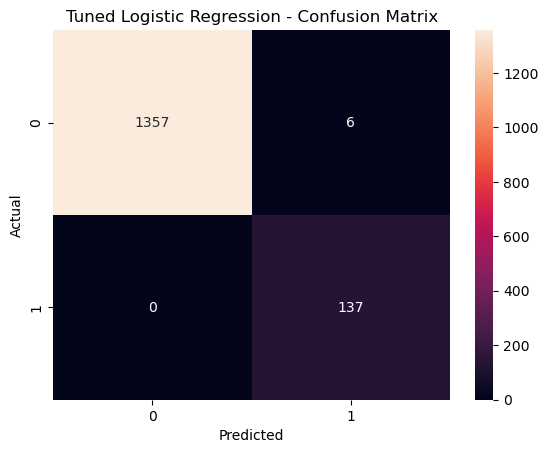

In [23]:
# Evaluate the tuned Logistic Regression model
pred_train_lr_best=best_lr_model.predict(x_train)
pred_test_lr_best=best_lr_model.predict(x_test)
print('Training accuracy:',accuracy_score(y_train,pred_train_lr_best))
print('Testing accuracy:',accuracy_score(y_test,pred_test_lr_best))
print('Training classification report:')
print(classification_report(y_train,pred_train_lr_best,digits=4,zero_division=0))
print('Testing classification report:')
print(classification_report(y_test,pred_test_lr_best,digits=4,zero_division=0))
sns.heatmap(confusion_matrix(y_test,pred_test_lr_best),annot=True,fmt='d')
plt.title('Tuned Logistic Regression - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

**Decision_Tree_Classifier**

In [24]:
# Train the model
from sklearn.tree import DecisionTreeClassifier
DT=DecisionTreeClassifier(random_state=42,class_weight='balanced')
DT.fit(x_train,y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,'balanced'


Training accuracy: 1.0
Testing accuracy: 0.992
Training classification report:
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000      3180
           1     1.0000    1.0000    1.0000       320

    accuracy                         1.0000      3500
   macro avg     1.0000    1.0000    1.0000      3500
weighted avg     1.0000    1.0000    1.0000      3500

Testing classification report:
              precision    recall  f1-score   support

           0     0.9956    0.9956    0.9956      1363
           1     0.9562    0.9562    0.9562       137

    accuracy                         0.9920      1500
   macro avg     0.9759    0.9759    0.9759      1500
weighted avg     0.9920    0.9920    0.9920      1500



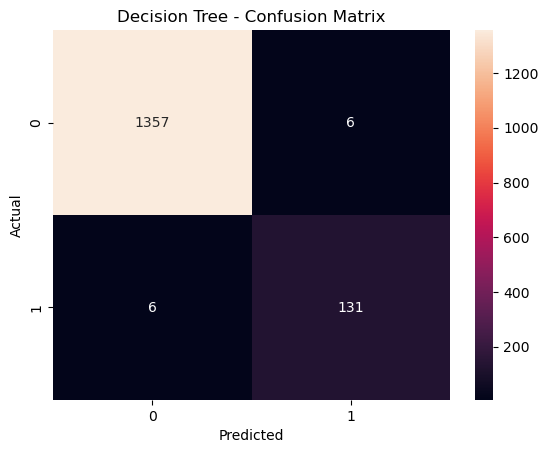

In [25]:
# Evaluate the Decision Tree model
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix
pred_train_dt=DT.predict(x_train)
pred_test_dt=DT.predict(x_test)
print('Training accuracy:',accuracy_score(y_train,pred_train_dt))
print('Testing accuracy:',accuracy_score(y_test,pred_test_dt))
print('Training classification report:')
print(classification_report(y_train,pred_train_dt,digits=4,zero_division=0))
print('Testing classification report:')
print(classification_report(y_test,pred_test_dt,digits=4,zero_division=0))
sns.heatmap(confusion_matrix(y_test,pred_test_dt),annot=True,fmt='d')
plt.title('Decision Tree - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

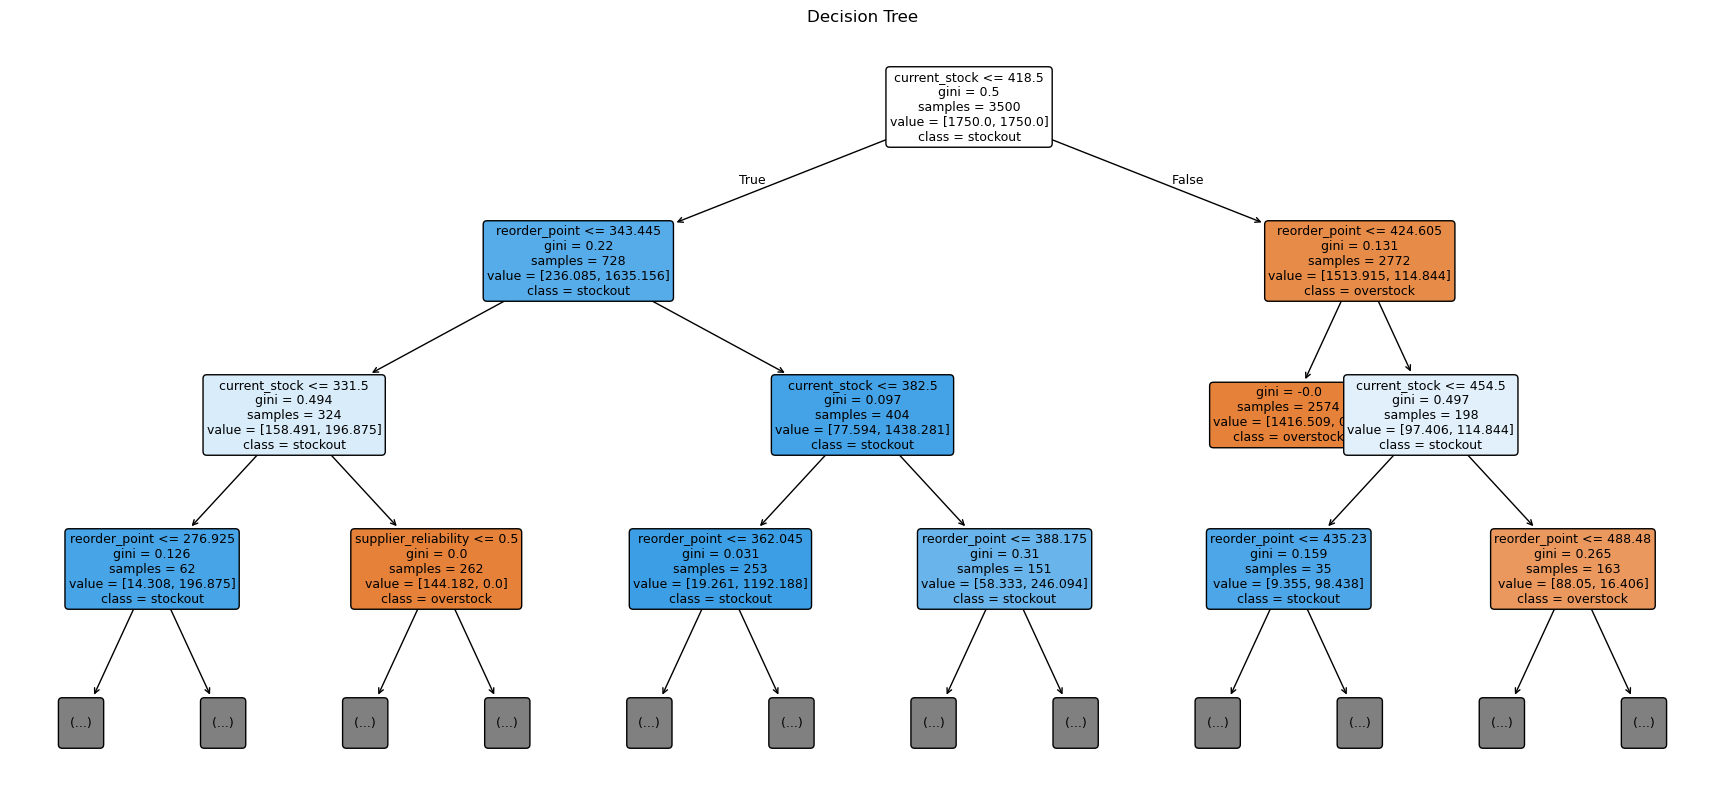

In [26]:
# Plot the tree
from sklearn.tree import plot_tree
plt.figure(figsize=(22,10))
plot_tree(DT,filled=True,feature_names=x_train.columns,class_names=['overstock','stockout'],max_depth=3,rounded=True,fontsize=9)
plt.title('Decision Tree')
plt.show()

**Decision_Tree_Classifier using HyperParameter_tuning**

In [27]:
# Tune the Decision Tree model
from sklearn.model_selection import GridSearchCV

dt_model=DecisionTreeClassifier(random_state=42,class_weight='balanced')

params={'criterion':['gini','entropy'],'splitter':['best','random'],'max_depth':range(1,10)}

dt_grid_search=GridSearchCV(estimator=dt_model,param_grid=params,cv=5)

dt_grid_search.fit(x_train,y_train)
print('Best parameters:',dt_grid_search.best_params_)
print('Best CV accuracy:',dt_grid_search.best_score_)
best_dt_model=dt_grid_search.best_estimator_


Best parameters: {'criterion': 'entropy', 'max_depth': 9, 'splitter': 'best'}
Best CV accuracy: 0.9877142857142858


Training accuracy: 1.0
Testing accuracy: 0.9886666666666667
Training classification report:
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000      3180
           1     1.0000    1.0000    1.0000       320

    accuracy                         1.0000      3500
   macro avg     1.0000    1.0000    1.0000      3500
weighted avg     1.0000    1.0000    1.0000      3500

Testing classification report:
              precision    recall  f1-score   support

           0     0.9949    0.9927    0.9938      1363
           1     0.9286    0.9489    0.9386       137

    accuracy                         0.9887      1500
   macro avg     0.9617    0.9708    0.9662      1500
weighted avg     0.9888    0.9887    0.9887      1500



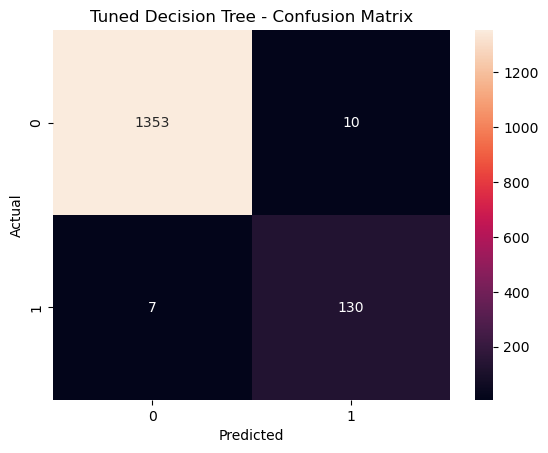

In [28]:
# Evaluate the Tuned Decision Tree model
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix
pred_train_dt_best=best_dt_model.predict(x_train)
pred_test_dt_best=best_dt_model.predict(x_test)
print('Training accuracy:',accuracy_score(y_train,pred_train_dt_best))
print('Testing accuracy:',accuracy_score(y_test,pred_test_dt_best))
print('Training classification report:')
print(classification_report(y_train,pred_train_dt_best,digits=4,zero_division=0))
print('Testing classification report:')
print(classification_report(y_test,pred_test_dt_best,digits=4,zero_division=0))
sns.heatmap(confusion_matrix(y_test,pred_test_dt_best),annot=True,fmt='d')
plt.title('Tuned Decision Tree - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

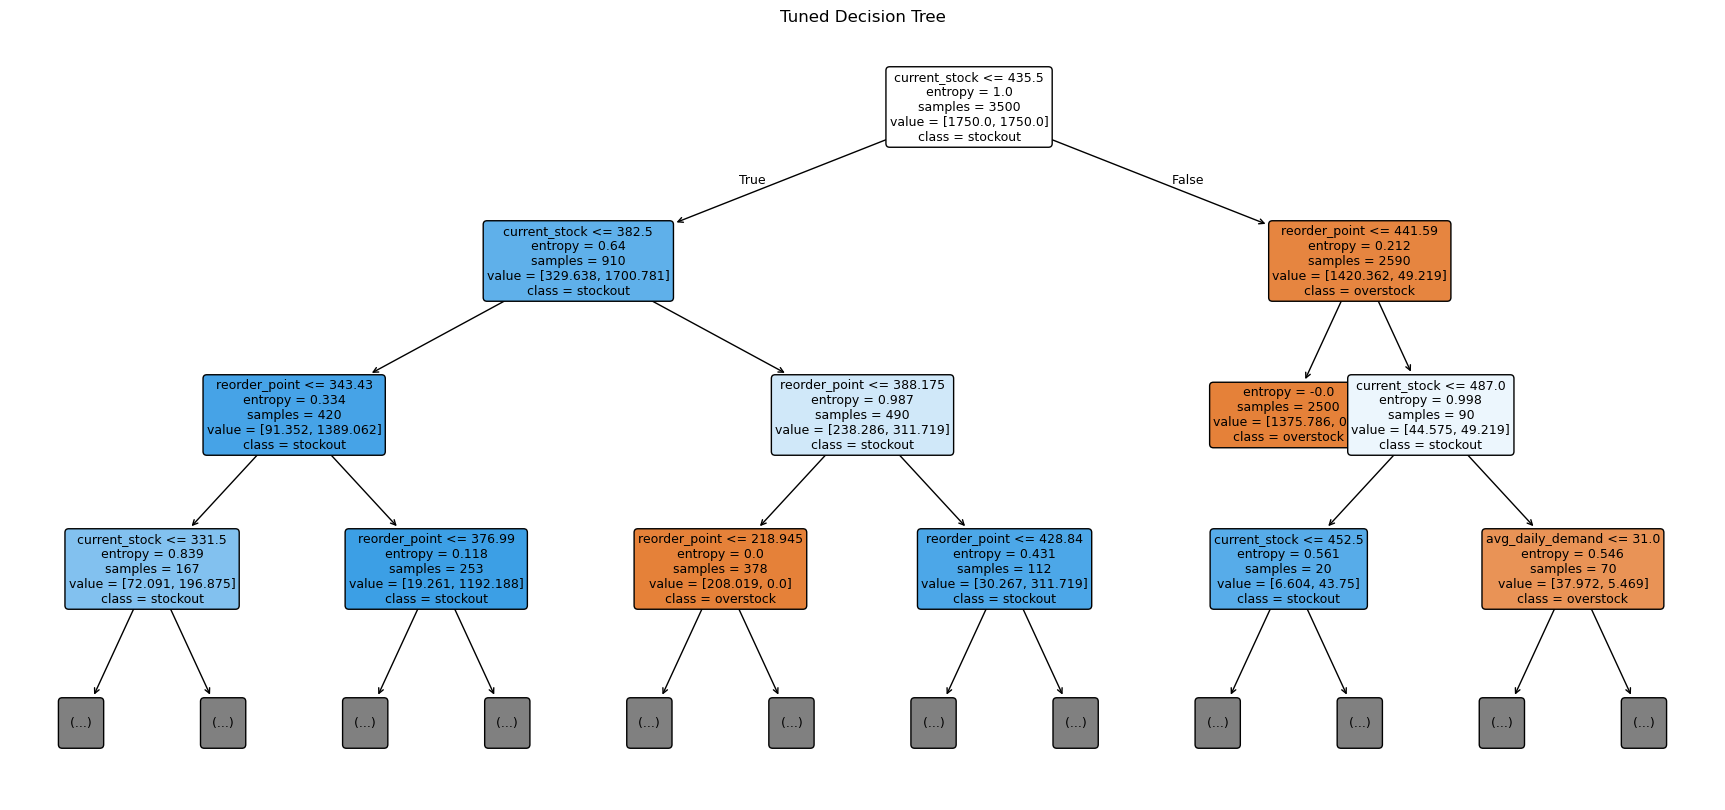

In [29]:
# Plot the tree
from sklearn.tree import plot_tree
plt.figure(figsize=(22,10))
plot_tree(best_dt_model,filled=True,feature_names=x_train.columns,class_names=['overstock','stockout'],max_depth=3,rounded=True,fontsize=9)
plt.title('Tuned Decision Tree')
plt.show()

**Random_Forest_Classifier**

In [30]:
# Train the model
from sklearn.ensemble import RandomForestClassifier
rf_model=RandomForestClassifier(n_estimators=100,random_state=42,max_samples=0.6,max_features=0.7,max_depth=10,class_weight='balanced')
rf_model.fit(x_train,y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,10
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,0.7
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


Training accuracy: 0.9997142857142857
Testing accuracy: 0.9926666666666667
Training classification report:
              precision    recall  f1-score   support

           0     0.9997    1.0000    0.9998      3180
           1     1.0000    0.9969    0.9984       320

    accuracy                         0.9997      3500
   macro avg     0.9998    0.9984    0.9991      3500
weighted avg     0.9997    0.9997    0.9997      3500

Testing classification report:
              precision    recall  f1-score   support

           0     0.9934    0.9985    0.9960      1363
           1     0.9846    0.9343    0.9588       137

    accuracy                         0.9927      1500
   macro avg     0.9890    0.9664    0.9774      1500
weighted avg     0.9926    0.9927    0.9926      1500



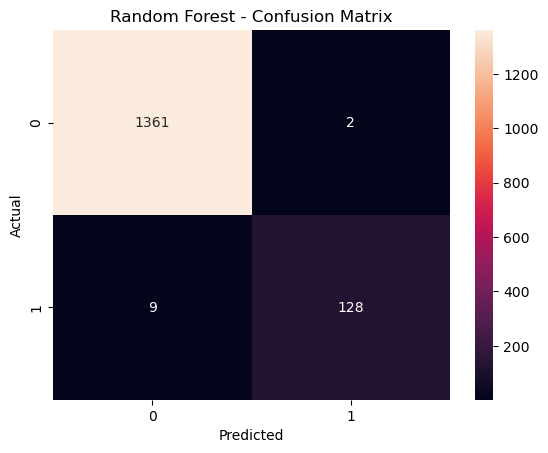

In [31]:
# Evaluate the Random Forest model
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix
pred_train_rf=rf_model.predict(x_train)
pred_test_rf=rf_model.predict(x_test)
print('Training accuracy:',accuracy_score(y_train,pred_train_rf))
print('Testing accuracy:',accuracy_score(y_test,pred_test_rf))
print('Training classification report:')
print(classification_report(y_train,pred_train_rf,digits=4,zero_division=0))
print('Testing classification report:')
print(classification_report(y_test,pred_test_rf,digits=4,zero_division=0))
sns.heatmap(confusion_matrix(y_test,pred_test_rf),annot=True,fmt='d')
plt.title('Random Forest - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

**Random_Forest_Classifier using HyperParameter_Tuning**

In [32]:
# Tune the Random Forest model
from sklearn.model_selection import GridSearchCV
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_samples': [0.6, 0.7, 0.8],
    'max_features': [0.6, 0.7, 0.8],
    'max_depth': [4, 6, 8, 10]
}
rf_search_model = RandomForestClassifier(random_state=42,class_weight='balanced')
rf_grid_search = GridSearchCV(estimator=rf_search_model, param_grid=param_grid, cv=5, scoring='f1', n_jobs=-1)
rf_grid_search.fit(x_train, y_train)
print("Best hyperparameters:", rf_grid_search.best_params_)
print("Best CV stockout F1:", rf_grid_search.best_score_)
best_rf_model=rf_grid_search.best_estimator_


Best hyperparameters: {'max_depth': 8, 'max_features': 0.8, 'max_samples': 0.6, 'n_estimators': 100}
Best CV stockout F1: 0.9472424603174604


Training accuracy: 0.9997142857142857
Testing accuracy: 0.9933333333333333
Training classification report:
              precision    recall  f1-score   support

           0     0.9997    1.0000    0.9998      3180
           1     1.0000    0.9969    0.9984       320

    accuracy                         0.9997      3500
   macro avg     0.9998    0.9984    0.9991      3500
weighted avg     0.9997    0.9997    0.9997      3500

Testing classification report:
              precision    recall  f1-score   support

           0     0.9942    0.9985    0.9963      1363
           1     0.9847    0.9416    0.9627       137

    accuracy                         0.9933      1500
   macro avg     0.9894    0.9701    0.9795      1500
weighted avg     0.9933    0.9933    0.9933      1500



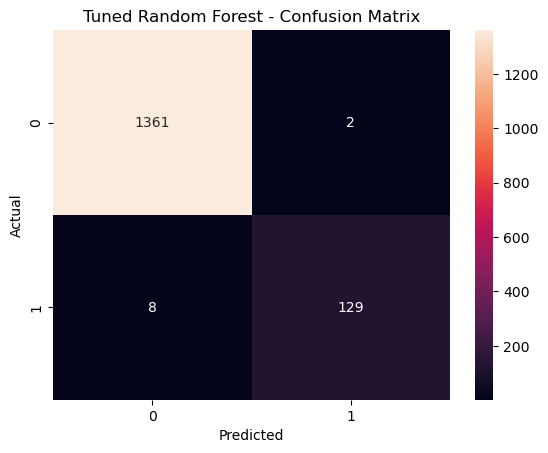

In [33]:
# Evaluate the Tuned Random Forest model
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix
pred_train_rf_best=best_rf_model.predict(x_train)
pred_test_rf_best=best_rf_model.predict(x_test)
print('Training accuracy:',accuracy_score(y_train,pred_train_rf_best))
print('Testing accuracy:',accuracy_score(y_test,pred_test_rf_best))
print('Training classification report:')
print(classification_report(y_train,pred_train_rf_best,digits=4,zero_division=0))
print('Testing classification report:')
print(classification_report(y_test,pred_test_rf_best,digits=4,zero_division=0))
sns.heatmap(confusion_matrix(y_test,pred_test_rf_best),annot=True,fmt='d')
plt.title('Tuned Random Forest - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

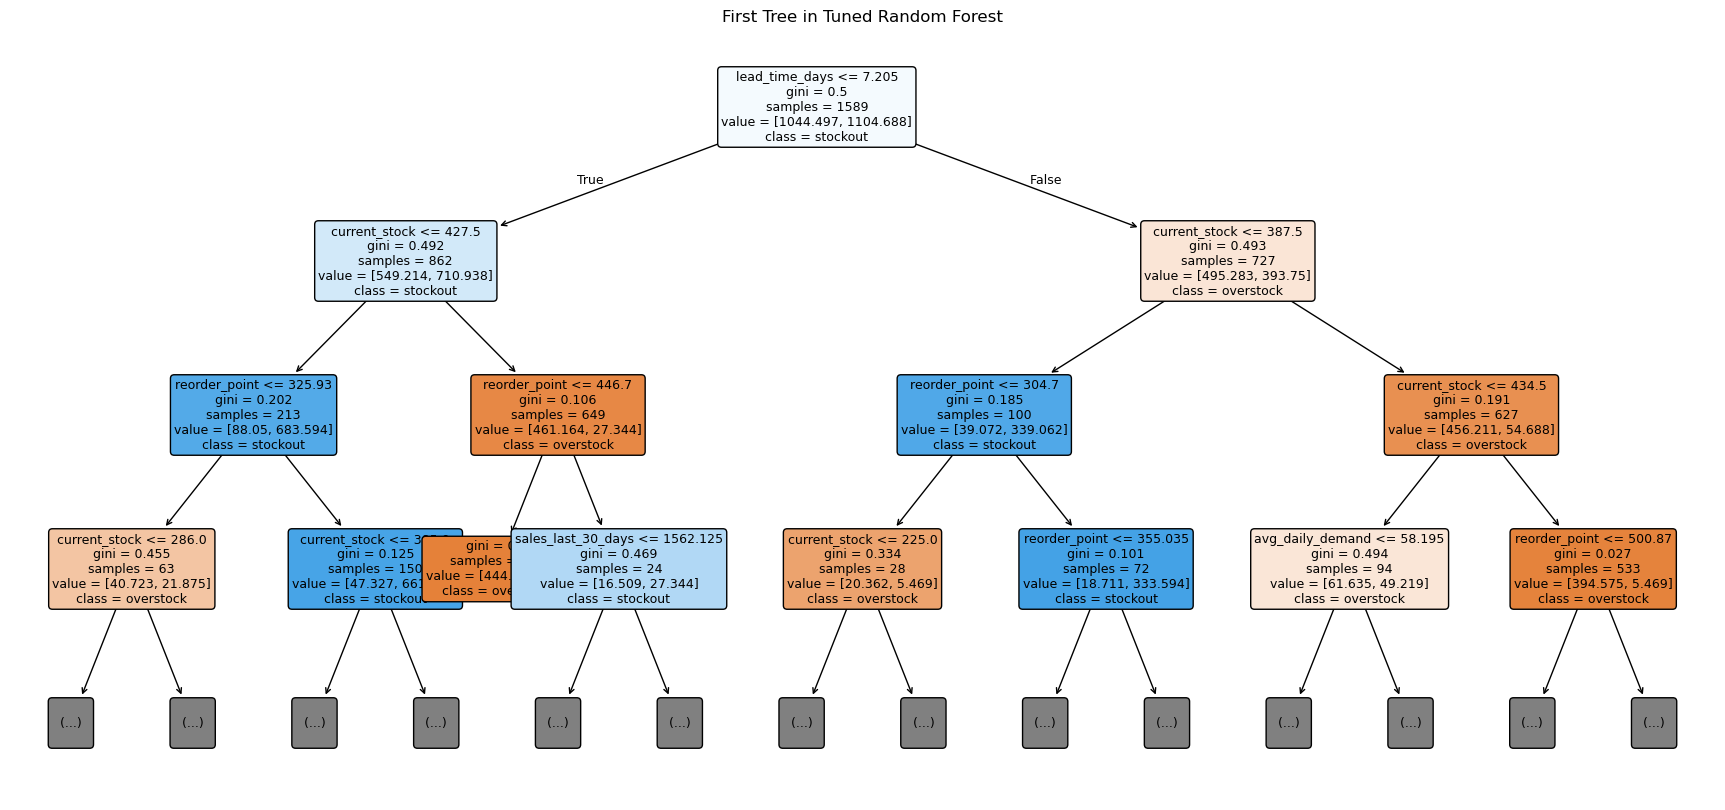

In [34]:
# Plot the tree
from sklearn.tree import plot_tree
plt.figure(figsize=(22,10))
plot_tree(best_rf_model.estimators_[0],filled=True,feature_names=x_train.columns,class_names=['overstock','stockout'],max_depth=3,rounded=True,fontsize=9)
plt.title('First Tree in Tuned Random Forest')
plt.show()

**Support_Vector_Classifier**

In [35]:
# Train the model
from sklearn.svm import SVC
svc=SVC(kernel='linear',class_weight='balanced',random_state=42)
svc.fit(x_train_scaled,y_train)

,C,1.0
,kernel,'linear'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,'balanced'
,verbose,False


Training accuracy: 0.9857142857142858
Testing accuracy: 0.9886666666666667
Training classification report:
              precision    recall  f1-score   support

           0     1.0000    0.9843    0.9921      3180
           1     0.8649    1.0000    0.9275       320

    accuracy                         0.9857      3500
   macro avg     0.9324    0.9921    0.9598      3500
weighted avg     0.9876    0.9857    0.9862      3500

Testing classification report:
              precision    recall  f1-score   support

           0     1.0000    0.9875    0.9937      1363
           1     0.8896    1.0000    0.9416       137

    accuracy                         0.9887      1500
   macro avg     0.9448    0.9938    0.9677      1500
weighted avg     0.9899    0.9887    0.9890      1500



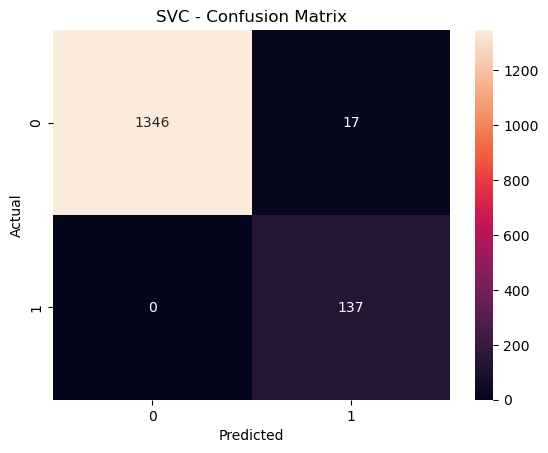

In [36]:
# Evaluate the SVC model
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix
pred_train_svc=svc.predict(x_train_scaled)
pred_test_svc=svc.predict(x_test_scaled)
print('Training accuracy:',accuracy_score(y_train,pred_train_svc))
print('Testing accuracy:',accuracy_score(y_test,pred_test_svc))
print('Training classification report:')
print(classification_report(y_train,pred_train_svc,digits=4,zero_division=0))
print('Testing classification report:')
print(classification_report(y_test,pred_test_svc,digits=4,zero_division=0))
sns.heatmap(confusion_matrix(y_test,pred_test_svc),annot=True,fmt='d')
plt.title('SVC - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

## Selection of Tuned Logistic Regression as the Best Model

Tuned Logistic Regression was selected as the best-performing candidate for the Inventory Stock Risk Prediction project based on the evaluation results of the models tested.

- **Highest Test Accuracy:** It achieved a test accuracy of 99.60%, outperforming the other evaluated models in the recorded results.
- **High Stockout Detection:** It achieved 100% recall for the stockout class, meaning that all actual stockout cases in the test dataset were correctly identified.
- **Hyperparameter Optimization:** GridSearchCV with 5-fold cross-validation was used to identify the best combination of hyperparameters using the macro F1-score as the evaluation metric.
- **Class Imbalance Handling:** The `class_weight='balanced'` parameter helps address the imbalance between overstock and stockout records.
- **Interpretability and Efficiency:** Logistic Regression is relatively simple to interpret and computationally efficient, making it a practical candidate for deployment.

### Conclusion

Based on the recorded test results, Tuned Logistic Regression is selected as the current best candidate for predicting inventory stock risk. Before final deployment, its performance should be validated using leakage-free preprocessing and independent test data to ensure that the high accuracy and stockout recall are reliable.

### **Deployement**

In [37]:
import joblib
joblib.dump(best_lr_model, 'model.pkl')

['model.pkl']

In [38]:
joblib.dump(oe, "ordinal_encoder.pkl")
joblib.dump(le, "label_encoder.pkl")

['label_encoder.pkl']